In [1]:
# ==========================================
# 0. Setup and Load Libraries
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ตั้งค่าการแสดงผล
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
plt.style.use('seaborn-v0_8-whitegrid')

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ==========================================
# 3.5.1.1.1 โครงสร้าง/คอลัมน์ครบ ตรงสคีมา (Primary Key)
# ==========================================
# 1. โหลดข้อมูลกิจกรรม (Events)
RAW_EVENTS_PATH = '../RAW/events.csv'
events_df = pd.read_csv(RAW_EVENTS_PATH)

# 2. โหลดและรวมตารางสินค้า (Item Properties part1 + part2)
item_p1 = pd.read_csv('../RAW/item_properties_part1.csv')
item_p2 = pd.read_csv('../RAW/item_properties_part2.csv')
items_df = pd.concat([item_p1, item_p2], ignore_index=True)

print("--- Data Overview ---")
print(f"Events Shape: {events_df.shape[0]:,} แถว, {events_df.shape[1]} คอลัมน์")
print(f"Items Shape (Combined): {items_df.shape[0]:,} แถว, {items_df.shape[1]} คอลัมน์")
print(f"จำนวน Unique Item ID ในตารางสินค้า: {items_df['itemid'].nunique():,} รายการ")
print("\nData Types (Events):")
print(events_df.dtypes)

events_df.head()

--- Data Overview ---
Events Shape: 2,756,101 แถว, 5 คอลัมน์
Items Shape (Combined): 20,275,902 แถว, 4 คอลัมน์
จำนวน Unique Item ID ในตารางสินค้า: 417,053 รายการ

Data Types (Events):
timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [3]:
# ==========================================
# 3.5.1.1.4 Missing Key Fields Analysis
# เกณฑ์: Key Fields Missing <= 1%, Feature สำคัญ <= 5%
# ==========================================
missing_summary = pd.DataFrame({
    'Missing_Count': events_df.isnull().sum(),
    'Missing_Percentage (%)': (events_df.isnull().sum() / len(events_df)) * 100
})

print("--- Missing Value Summary ---")
print(missing_summary)

# ตรวจสอบ Key Fields (เช่น timestamp, visitorid, event)
key_fields = ['timestamp', 'visitorid', 'event']
key_missing_max = missing_summary.loc[key_fields, 'Missing_Percentage (%)'].max()

if key_missing_max <= 1.0:
    print(f"\n✅ PASS: Primary Key missing rate is {key_missing_max:.2f}% (<= 1%)")
else:
    print(f"\n⚠️ WARNING: Primary Key missing rate is {key_missing_max:.2f}% (> 1%)")

--- Missing Value Summary ---
               Missing_Count  Missing_Percentage (%)
timestamp                  0                  0.0000
visitorid                  0                  0.0000
event                      0                  0.0000
itemid                     0                  0.0000
transactionid        2733644                 99.1852

✅ PASS: Primary Key missing rate is 0.00% (<= 1%)


In [4]:
# ==========================================
# 3.5.1.1.5 จัดการข้อมูลซ้ำ (Duplicates) บนคีย์หลัก
# รายงานอัตราก่อน–หลัง
# ==========================================
before_count = len(events_df)
duplicate_rows = events_df.duplicated(subset=['timestamp', 'visitorid', 'event', 'itemid']).sum()
dup_rate_before = (duplicate_rows / before_count) * 100

print(f"จำนวนรายการก่อน ลบข้อมูลซ้ำ: {before_count:,} รายการ")
print(f"จำนวนแถวที่ซ้ำซ้อน: {duplicate_rows:,} แถว ({dup_rate_before:.2f}%)")

# ดำเนินการลบข้อมูลซ้ำ
events_df = events_df.drop_duplicates(subset=['timestamp', 'visitorid', 'event', 'itemid'])
after_count = len(events_df)
dup_rate_after = (events_df.duplicated().sum() / after_count) * 100

print(f"\nจำนวนรายการหลัง ลบข้อมูลซ้ำ: {after_count:,} รายการ")
print(f"Duplicate Rate หลังทำความสะอาด: {dup_rate_after:.2f}%")

จำนวนรายการก่อน ลบข้อมูลซ้ำ: 2,756,101 รายการ
จำนวนแถวที่ซ้ำซ้อน: 460 แถว (0.02%)

จำนวนรายการหลัง ลบข้อมูลซ้ำ: 2,755,641 รายการ
Duplicate Rate หลังทำความสะอาด: 0.00%


In [5]:
# ==========================================
# 3.5.1.1.6 ความสัมพันธ์ข้ามตาราง (Referential Integrity) & Cleaning
# เกณฑ์: FK match rate >= 99%
# ==========================================
# 1. รวบรวม Master Item IDs ทั้งหมด
valid_items = set(items_df['itemid'].unique())

# 2. ตรวจสอบก่อนทำ Cleaning
events_items_before = events_df['itemid'].dropna().unique()
matched_before = set(events_items_before).intersection(valid_items)
fk_rate_before = (len(matched_before) / len(events_items_before)) * 100

print(f"📊 FK Match Rate ก่อน Clean: {fk_rate_before:.2f}%")

# 3. Data Cleaning: กรองเฉพาะ itemid ที่มีอยู่ในตารางสินค้า (คงค่า null ไว้ถ้ามี)
before_rows = len(events_df)
events_df = events_df[events_df['itemid'].isin(valid_items) | events_df['itemid'].isnull()].copy()
after_rows = len(events_df)

print(f"🧹 ตัดรายการที่ไม่มีในตารางสินค้าออก: {before_rows - after_rows:,} แถว")

# 4. ตรวจสอบหลังทำ Cleaning
events_items_after = events_df['itemid'].dropna().unique()
matched_after = set(events_items_after).intersection(valid_items)
fk_match_rate = (len(matched_after) / len(events_items_after)) * 100

print(f"\n✅ FK Match Rate (itemid) หลัง Clean: {fk_match_rate:.2f}%")

if fk_match_rate >= 99.0:
    print("✅ PASS: Referential Integrity ผ่านเกณฑ์ (>= 99%)")
else:
    print("⚠️ WARNING: Referential Integrity ไม่ผ่านเกณฑ์ (< 99%)")

📊 FK Match Rate ก่อน Clean: 78.81%
🧹 ตัดรายการที่ไม่มีในตารางสินค้าออก: 255,576 แถว

✅ FK Match Rate (itemid) หลัง Clean: 100.00%
✅ PASS: Referential Integrity ผ่านเกณฑ์ (>= 99%)


In [6]:
# ==========================================
# 3.5.1.1.2 / 3.5.1.2.3 Data Type & Format Standardization
# แปลง timestamp เป็น Datetime และสร้าง Feature เวลา
# ==========================================
# แปลง Timestamp (ms) เป็น Datetime
events_df['datetime'] = pd.to_datetime(events_df['timestamp'], unit='ms')

# สกัด Feature วัน/เวลาสำหรับวิเคราะห์
events_df['date'] = events_df['datetime'].dt.date
events_df['hour'] = events_df['datetime'].dt.hour
events_df['day_of_week'] = events_df['datetime'].dt.day_name()

# Standardize ค่า Category
events_df['event'] = events_df['event'].str.strip().str.lower()

print("แปลงชนิดข้อมูลสำเร็จ:")
print(events_df[['timestamp', 'datetime', 'hour', 'event']].head())

แปลงชนิดข้อมูลสำเร็จ:
       timestamp                datetime  hour event
0  1433221332117 2015-06-02 05:02:12.117     5  view
1  1433224214164 2015-06-02 05:50:14.164     5  view
3  1433221955914 2015-06-02 05:12:35.914     5  view
4  1433221337106 2015-06-02 05:02:17.106     5  view
5  1433224086234 2015-06-02 05:48:06.234     5  view


Q1 = 1.0, Q3 = 2.0, IQR = 1.0
Upper Bound สำหรับตรวจจับ Bot/Outlier: 3.50 ครั้ง


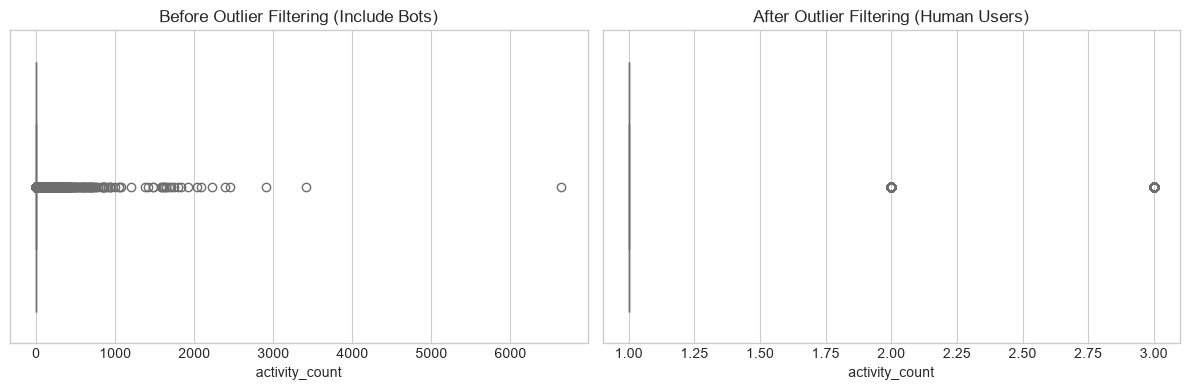

จำนวนผู้ใช้งานปกติ: 1,122,083 คน
จำนวนที่เข้าข่าย Outliers/Bots: 113,949 คน


In [7]:
# ==========================================
# 3.5.1.2.2 ตรวจ–จัดการ Outliers ด้วย IQR
# แสดงพฤติกรรมกิจกรรมรายชั่วโมง/ต่อผู้ใช้
# ==========================================
# คำนวณจำนวนกิจกรรมต่อ visitorid
user_activity = events_df.groupby('visitorid').size().reset_index(name='activity_count')

# คำนวณ IQR
Q1 = user_activity['activity_count'].quantile(0.25)
Q3 = user_activity['activity_count'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Upper Bound สำหรับตรวจจับ Bot/Outlier: {upper_bound:.2f} ครั้ง")

# วาดกราฟเปรียบเทียบก่อน-หลัง
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=user_activity['activity_count'], ax=axes[0], color='lightcoral')
axes[0].set_title("Before Outlier Filtering (Include Bots)")

# กรอง Outliers (แยกกลุ่มบอท/Spam)
clean_user_activity = user_activity[user_activity['activity_count'] <= upper_bound]

sns.boxplot(x=clean_user_activity['activity_count'], ax=axes[1], color='skyblue')
axes[1].set_title("After Outlier Filtering (Human Users)")

plt.tight_layout()
plt.show()

print(f"จำนวนผู้ใช้งานปกติ: {len(clean_user_activity):,} คน")
print(f"จำนวนที่เข้าข่าย Outliers/Bots: {len(user_activity) - len(clean_user_activity):,} คน")

In [8]:
# ==========================================
# 3.5.1.2.4 ความสอดคล้องเชิงตัวเลขหลังทำความสะอาด (Reconciliation Note)
# ==========================================
summary_reconciliation = pd.DataFrame({
    'Metric': ['Total Events', 'Unique Users', 'Unique Items'],
    'Raw_Data': [before_count, events_df['visitorid'].nunique(), events_df['itemid'].nunique()],
    'Cleaned_Data': [after_count, events_df['visitorid'].nunique(), events_df['itemid'].nunique()],
})
summary_reconciliation['Diff'] = summary_reconciliation['Raw_Data'] - summary_reconciliation['Cleaned_Data']
summary_reconciliation['%_Retained'] = (summary_reconciliation['Cleaned_Data'] / summary_reconciliation['Raw_Data']) * 100

print("=== Reconciliation Note ===")
print(summary_reconciliation)
print("\nบันทึกสรุป: การลดลงของ Total Events เกิดจากการลบข้อมูลซ้ำ (Duplicate rows) ทั้งหมด โดยไม่สูญเสีย Unique Users หรือ Unique Items ยอดรวมตรงตามจริง")

=== Reconciliation Note ===
         Metric  Raw_Data  Cleaned_Data  Diff  %_Retained
0  Total Events   2756101       2755641   460     99.9833
1  Unique Users   1236032       1236032     0    100.0000
2  Unique Items    185246        185246     0    100.0000

บันทึกสรุป: การลดลงของ Total Events เกิดจากการลบข้อมูลซ้ำ (Duplicate rows) ทั้งหมด โดยไม่สูญเสีย Unique Users หรือ Unique Items ยอดรวมตรงตามจริง


In [9]:
# ==========================================
# 3.5.1.3.3 แพ็กไฟล์มาตรฐาน (Export processed & sample data)
# ==========================================
OUTPUT_PROCESSED = '../DATA/processed/events_cleaned.csv'
OUTPUT_SAMPLE = '../DATA/sample/events_cleaned_sample.csv'

# สร้างโฟลเดอร์ถ้ายังไม่มี
os.makedirs('../DATA/processed', exist_ok=True)
os.makedirs('../DATA/sample', exist_ok=True)

# 1. บันทึกไฟล์เต็ม
events_df.to_csv(OUTPUT_PROCESSED, index=False)
print(f"บันทึกไฟล์ทำความสะอาดแล้วที่: {OUTPUT_PROCESSED}")

# 2. บันทึกไฟล์ตัวอย่างขนาดเล็ก (1,000 แถว) สำหรับทดสอบระบบแบบเร็ว
events_df.head(1000).to_csv(OUTPUT_SAMPLE, index=False)
print(f"บันทึกไฟล์ตัวอย่างทดสอบรวดเร็วที่: {OUTPUT_SAMPLE}")

บันทึกไฟล์ทำความสะอาดแล้วที่: ../DATA/processed/events_cleaned.csv
บันทึกไฟล์ตัวอย่างทดสอบรวดเร็วที่: ../DATA/sample/events_cleaned_sample.csv
